In [9]:
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy.signal as signal
import src.helper
import src.location
import src.mooring
import src.plots
import src.spectra

# import seaborn as sns
from pandas.api.types import is_numeric_dtype
# sns.set_theme(style="white")

### Load Data

In [10]:
# load all 7 moorings as dataframes
list_of_moorings = src.helper.load_pickle(name="../../data/mooring/list_of_moorings.pkl")
mooring_C = src.helper.load_pickle(name="../preprocessing/mooring_C.pkl")
region_categorization = pd.read_csv("../../derived_data/rcm_infos.csv", index_col=0)
names = ["A", "B", "C", "D", "E", "F", "G"]
moorings = {}
for name, mooring in zip(names, list_of_moorings):
    moorings[name] = mooring.set_index("time")
    print(mooring.location, list(mooring.columns))

(-63.40,-52.29) ['time', '299', '505', '614']
(-63.51,-51.64) ['time', '1318', '1513', '1625']
(-63.66,-50.81) ['time', '2143', '2350', '750']
(-63.78,-50.09) ['time', '2400', '2615', '2724']
(-63.92,-49.27) ['time', '3036', '3299', '3358']
(-64.07,-48.38) ['time', '3835']
(-64.22,-47.49) ['time', '4120', '4160']


### Align Time series

In [11]:
def find_latest_start(moorings):
    starttimes = []
    for i, (name, mooring) in enumerate(moorings.items()):
        for j, col in enumerate(mooring.columns):
            if name == "C":
                series = pd.Series(
                    index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values
                )
            else:
                series = mooring[col]
            starttimes.append(series.index[0])

    latest_start = np.max(np.array(starttimes))
    return latest_start


common_start_time = find_latest_start(moorings)
print(f"{common_start_time = }")

common_start_time = Timestamp('2017-01-28 11:49:59.999996')


# Sanity Check

In [12]:
common_start_time = pd.to_datetime(find_latest_start(moorings)).round("h")


def get_2350_velocity():
    for i, (name, mooring) in enumerate(moorings.items()):
        for j, col in enumerate(mooring.columns):
            if name != "C":
                continue

            series = pd.Series(index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values)
            series = series[series.index.dropna()]
            assert series.index.is_monotonic_increasing
            series = series.loc[pd.to_datetime(common_start_time) :]
            mooring_id = i
            col_name = name
            if int(col) == 2350:
                return series

In [13]:
def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(
        window
    )  # smooth by convolving speed with window
    return smoothed

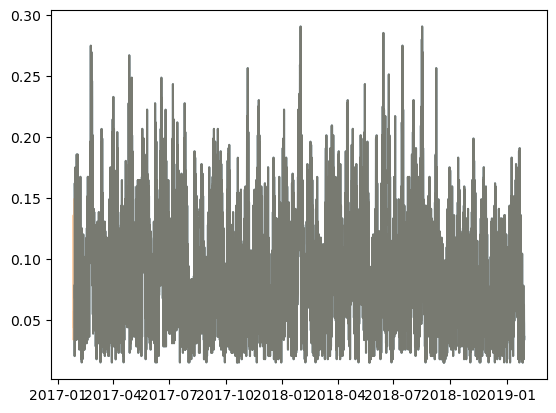

In [14]:
series = get_2350_velocity()
raw_series = pd.Series(index=mooring_C[f"time_{2350}"].values, data=mooring_C["2350"].values)


_, ax = plt.subplots()
ax.plot(series.index, smooth(series.abs(), 1))
ax.plot(raw_series.index, smooth(raw_series.abs(), 1), alpha=0.4)
# ax.plot(momentum_transfer["C"].index, momentum_transfer["C"].abs())

In [15]:
hke = pd.read_csv("../../derived_data/HKE.csv", index_col=0, header=[0, 1])
hke.index = pd.to_datetime(hke.index).floor("d")
# results.index = multi_index
hke

A                             B                      \
                 299       505       614      1318      1513      1625   
2017-01-28  0.001343  0.001434  0.001364  0.000985  0.000828  0.000685   
2017-02-02  0.001525  0.001702  0.001602  0.001010  0.000878  0.000682   
2017-02-07  0.001605  0.001858  0.001713  0.001068  0.000879  0.000655   
2017-02-12  0.001395  0.001652  0.001536  0.001051  0.000782  0.000554   
2017-02-17  0.001555  0.001522  0.001387  0.001086  0.000828  0.000589   
...              ...       ...       ...       ...       ...       ...   
2018-12-09  0.000396  0.000788  0.000977  0.000715  0.000690       NaN   
2018-12-14  0.000407  0.000836  0.001190  0.000768  0.000767       NaN   
2018-12-19  0.000380  0.000849  0.001207  0.000748  0.000729       NaN   
2018-12-24  0.000338  0.000768  0.001017  0.000680  0.000661       NaN   
2018-12-29  0.000377  0.000881  0.001106  0.000703  0.000797       NaN   

                   C             control         D                      \
                2143      2350       750      2400      2615      2724   
2017-01-28  0.000707  0.000721  0.000294  0.000368  0.000463  0.000632   
2017-02-02  0.000820  0.000767  0.000312  0.000333  0.000458  0.000674   
2017-02-07  0.000847  0.000761  0.000330  0.000330  0.000441  0.000644   
2017-02-12  0.000791  0.000742  0.000329  0.000321  0.000399  0.000570   
2017-02-17  0.000878  0.001026  0.000346  0.000357  0.000402  0.000494   
...              ...       ...       ...       ...       ...       ...   
2018-12-09       NaN  0.000541       NaN       NaN       NaN       NaN   
2018-12-14       NaN  0.000648       NaN       NaN       NaN       NaN   
2018-12-19       NaN  0.000695       NaN       NaN       NaN       NaN   
2018-12-24       NaN  0.000753       NaN       NaN       NaN       NaN   
2018-12-29       NaN  0.000766       NaN       NaN       NaN       NaN   

                   E                             F         G            
                3036      3299      3358      3835      4120      4160  
2017-01-28  0.000165  0.000333  0.000448  0.000304  0.000195  0.000166  
2017-02-02  0.000212  0.000350  0.000468  0.000279  0.000161  0.000139  
2017-02-07  0.000226  0.000376  0.000488  0.000272  0.000183  0.000131  
2017-02-12  0.000264  0.000455  0.000598  0.000305  0.000246  0.000142  
2017-02-17  0.000276  0.000558  0.000792  0.000350  0.000341  0.000168  
...              ...       ...       ...       ...       ...       ...  
2018-12-09       NaN       NaN       NaN  0.000180  0.000118  0.000111  
2018-12-14       NaN       NaN       NaN  0.000209  0.000122  0.000119  
2018-12-19       NaN       NaN       NaN  0.000202  0.000142  0.000116  
2018-12-24       NaN       NaN       NaN  0.000211  0.000141  0.000124  
2018-12-29       NaN       NaN       NaN       NaN       NaN       NaN  

[141 rows x 18 columns]

<Axes: >

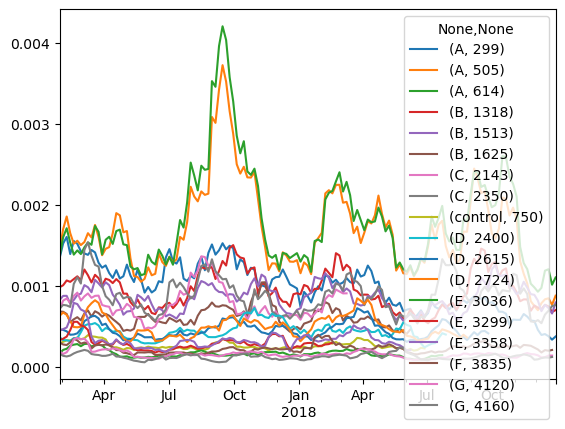

In [16]:
hke.plot()

<Axes: >

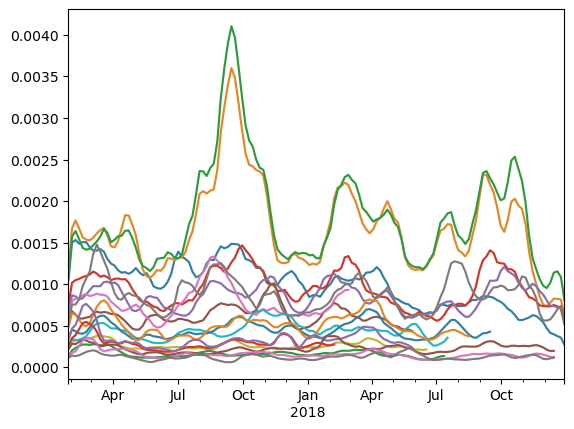

In [17]:
smoothed_hke = hke.apply(smooth, args=(5,))
smoothed_hke.plot(legend=False)
smoothed_hke.plot(alpha=0.1, ax=plt.gca(), legend=False)

In [18]:
corr = smoothed_hke.corr(method="pearson")
# Fill diagonal and upper half with NaNs
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr[mask] = np.nan
(
    corr.style.background_gradient(cmap="coolwarm", axis=None, vmin=-1, vmax=1)
    .highlight_null(color="#f1f1f1")  # Color NaNs grey
    .format(precision=2)
)

In [19]:
corr = hke.corr(method="spearman")
# Fill diagonal and upper half with NaNs
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr[mask] = np.nan
(
    corr.style.background_gradient(cmap="coolwarm", axis=None, vmin=-1, vmax=1)
    .highlight_null(color="#f1f1f1")  # Color NaNs grey
    .format(precision=2)
)

In [20]:
# results.resample("ME").mean()
# corr = results.resample("ME").mean().corr(method='spearman')
# # Fill diagonal and upper half with NaNs
# mask = np.zeros_like(corr, dtype=bool)
# mask[np.triu_indices_from(mask)] = True
# corr[mask] = np.nan
# (corr
#  .style
#  .background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1)
#  .highlight_null(color='#f1f1f1')  # Color NaNs grey
#  .format(precision=2))

In [21]:
import seaborn as sns

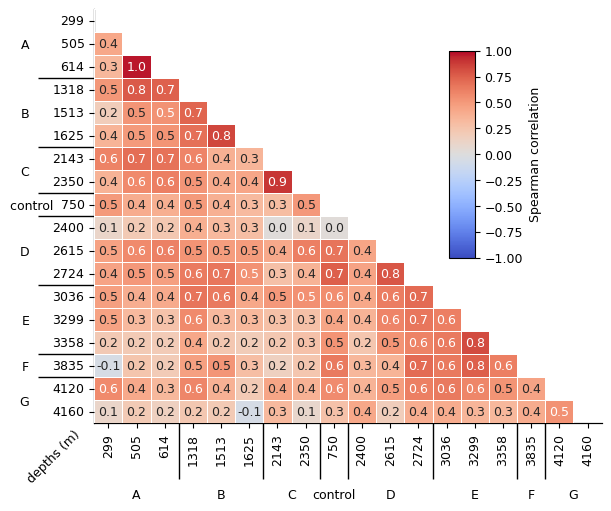

In [22]:
cm = 1 / 2.54  # centimeters in inches
TWO_COLUMN_WIDTH = 12

plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

corr = smoothed_hke.corr(method="spearman")
# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")

# Generate a custom diverging colormap
cmap = "coolwarm"  # sns.color_palette("vlag", as_cmap=True)
# Draw the heatmap with the mask and correct aspect ratio
matrix = sns.heatmap(
    corr,
    mask=mask,
    cmap=cmap,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar=False,
    cbar_kws={"shrink": 0.4},  # , set_frame_on:True},
    annot=True,
    annot_kws={"fontsize": 9},
    fmt=".1f",
    xticklabels=corr.index.get_level_values(1),
    yticklabels=corr.index.get_level_values(1),
)


cax = ax.inset_axes([0.7, 0.4, 0.05, 0.5])
norm = mpl.colors.Normalize(vmin=-1, vmax=1)
fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cax,
    orientation="vertical",
    label="Spearman correlation",
    shrink=0.1,
)

ax.set(xlabel="", ylabel="")
# label the classes:
sec = ax.secondary_yaxis(location=0)
labels = [f"{s:{' '}<16}" for s in pd.unique(corr.index.get_level_values(0))]
sec.set_yticks([1.5, 4.5, 7, 8.5, 10.5, 13.5, 15.5, 17], labels=labels)
sec.tick_params("y", length=0)
# lines between the classes:
sec2 = ax.secondary_yaxis(location=0)
sec2.set_yticks([3, 6, 8, 9, 12, 15, 16], labels=[])
sec2.tick_params("y", length=40, width=1)

sec = ax.secondary_xaxis(location=0)
newline = "\n"
labels = [f"{4 * newline}{mooring}" for mooring in pd.unique(corr.index.get_level_values(0))]
# for i,label in enumerate(labels.copy()):
#     if "control" in label:
#         labels[i] = "\n"+label
sec.set_xticks([1.5, 4.5, 7, 8.5, 10.5, 13.5, 15.5, 17], labels=labels)
sec.tick_params("x", length=0)
# lines between the classes:
sec2 = ax.secondary_xaxis(location=0)
sec2.set_xticks([3, 6, 8, 9, 12, 15, 16], labels=[])
sec2.tick_params("x", length=40, width=1)
ax.tick_params(axis="x", labelrotation=90)
# ax.set_title("Pairwise Correlation")
ax.text(-0.08, -0.08, "depths (m)", transform=ax.transAxes, ha="center", va="center", rotation=45)
fig.savefig("./HKE_pair_correlation.pdf")

## Atmospheric forcing

In [23]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    for i, col in enumerate(df.columns):
        if not is_numeric_dtype(df[col]):
            df[col] = df[col].str.replace("i", "j").apply(lambda x: complex(x))
    df = df.fillna(0)
    return df

In [24]:
energy_transfer = pd.read_csv("../../derived_data/daily_energy_transfer.csv")
energy_transfer.set_index(pd.to_datetime(energy_transfer["Unnamed: 0"]), inplace=True)
energy_transfer.drop("Unnamed: 0", inplace=True, axis="columns")
energy_transfer = energy_transfer.loc[smoothed_hke.index[0] :]
energy_transfer.head()

,A,B,C,D,E,F,G
Unnamed: 0,,,,,,,
2017-01-28,1.886580e-03,0.000831,-0.000031,-0.000393,-0.000921,0.001503,0.001621
2017-02-02,-2.267926e-07,0.000137,0.000251,-0.000189,-0.000296,0.000139,0.000074
2017-02-07,2.865823e-03,-0.000235,-0.000639,-0.000215,0.000149,0.002260,0.001245
2017-02-12,1.369518e-03,-0.000237,-0.000653,-0.000726,-0.000593,0.001345,0.001847
2017-02-17,-2.166595e-04,0.000085,0.000161,0.000180,0.000143,0.000121,-0.000224


In [25]:
momentum_transfer = pd.read_csv("../../derived_data/daily_momentum_transfer.csv")
momentum_transfer.set_index(pd.to_datetime(momentum_transfer["Unnamed: 0"]), inplace=True)
momentum_transfer.drop("Unnamed: 0", inplace=True, axis="columns")
momentum_transfer = momentum_transfer.loc[smoothed_hke.index[0] :]
for i, col in enumerate(momentum_transfer.columns):
    if not is_numeric_dtype(momentum_transfer[col]):
        momentum_transfer[col] = (
            momentum_transfer[col].str.replace("i", "j").apply(lambda x: complex(x))
        )
momentum_transfer = momentum_transfer.dropna(axis="index", how="all")

In [26]:
momentum_transfer

,A,B,C,D,E,F,G
Unnamed: 0,,,,,,,
2017-01-28,0.061258-0.036361j,0.059420-0.032676j,0.059158-0.030403j,0.052734-0.025628j,0.053446-0.023990j,0.050476-0.020578j,0.053988-0.020147j
2017-02-02,0.002443+0.005325j,0.001333+0.004272j,0.001557+0.004583j,0.001319+0.004695j,0.001008+0.004049j,0.000070+0.002689j,-0.000807+0.003361j
2017-02-07,0.064739-0.030513j,0.046751-0.021108j,0.044863-0.019139j,0.029880-0.014111j,0.030370-0.013275j,0.023013-0.009660j,0.021083-0.007570j
2017-02-12,0.025823-0.022703j,0.019025-0.018736j,0.020588-0.018881j,0.022664-0.017807j,0.026464-0.018268j,0.027787-0.015978j,0.028546-0.013488j
2017-02-17,-0.005404+0.002064j,-0.005228+0.001926j,-0.005751+0.002754j,-0.005147+0.002940j,-0.005223+0.003623j,-0.005031+0.004956j,-0.004729+0.006385j
...,...,...,...,...,...,...,...
2018-12-09,0.026689-0.023778j,0.023919-0.018785j,0.023759-0.016691j,0.021027-0.011978j,0.021412-0.010315j,0.022502-0.008105j,0.021309-0.006441j
2018-12-14,0.091506+0.004680j,0.083225+0.003825j,0.079632+0.002904j,0.069090+0.002838j,0.062272+0.001811j,0.051224-0.001170j,0.056333-0.003104j
2018-12-19,0.007461-0.009476j,0.004368-0.008870j,0.003817-0.007979j,0.003338-0.007659j,0.002753-0.004527j,-0.000200-0.002883j,0.000374-0.003397j


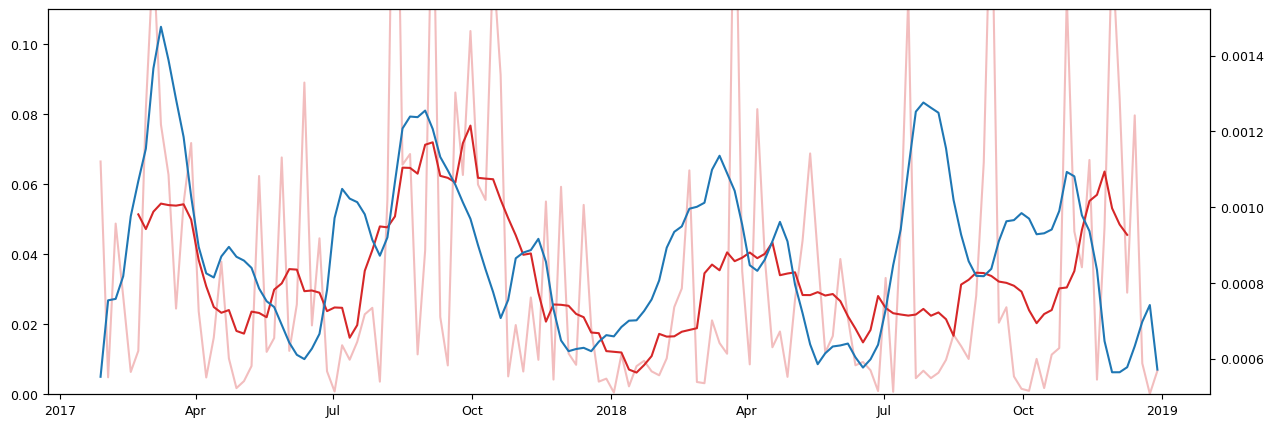

In [27]:
fig, ax = plt.subplots(1, figsize=(15, 5))
ax.plot(
    momentum_transfer.index,
    momentum_transfer["C"].abs().rolling(10, center=True).mean(),
    label="tau",
    color="tab:red",
)
ax.plot(
    momentum_transfer.index, momentum_transfer["C"].abs(), label="tau", color="tab:red", alpha=0.3
)
ax2 = ax.twinx()
ax2.plot(smoothed_hke.index, smoothed_hke["C", "2350"], label="hke")
ax.set_ylim(0, 0.11)
# ax.set_ylim(0.06,0.16)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

In [28]:
def pairwise_HKE_Pi_correlation(hke, pi, method):
    assert np.all(hke.index == pi.index)
    correlations = []
    for location, column in zip(hke.columns.get_level_values(0), hke.columns):
        if location == "control":
            location = "C"
        pair = pd.DataFrame(index=hke.index, data={"hke": hke[column], "energy": pi[location]})
        pair.dropna(axis="rows", inplace=True)
        corr = pair["hke"].corr(pair["energy"], method=method, min_periods=12)
        correlations.append(corr)
        # print(corr)
    return pd.Series(index=hke.columns, data=correlations)

In [29]:
"""
resampled =results.resample("MS").mean()
fig, ax  = plt.subplots(1)
for col in resampled.columns:
    plt.plot(resampled.index+pd.Timedelta(days=15), resampled[col])
for col in results.columns:
    plt.plot(results.index, results[col], alpha=0.2)
"""

'\nresampled =results.resample("MS").mean()\nfig, ax  = plt.subplots(1)\nfor col in resampled.columns:\n    plt.plot(resampled.index+pd.Timedelta(days=15), resampled[col])\nfor col in results.columns:\n    plt.plot(results.index, results[col], alpha=0.2)\n'

In [30]:
# pair = pd.DataFrame(index=energy_transfer.index, data={"hke":smoothed_hke["C", "2143"], "energy":energy_transfer["C"]})

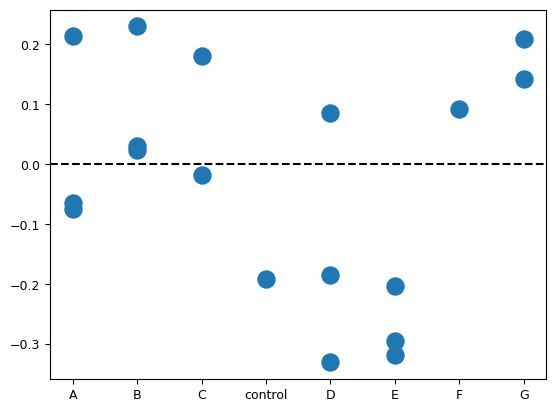

In [31]:
corr = pairwise_HKE_Pi_correlation(smoothed_hke, energy_transfer, method="spearman")
plt.scatter(corr.index.get_level_values(0), corr, s=150)
plt.gca().axhline(0, color="k", ls="--")

In [32]:
print(smoothed_hke.index)
print(momentum_transfer.index)
print(energy_transfer.index)

DatetimeIndex(['2017-01-28', '2017-02-02', '2017-02-07', '2017-02-12',
               '2017-02-17', '2017-02-22', '2017-02-27', '2017-03-04',
               '2017-03-09', '2017-03-14',
               ...
               '2018-11-14', '2018-11-19', '2018-11-24', '2018-11-29',
               '2018-12-04', '2018-12-09', '2018-12-14', '2018-12-19',
               '2018-12-24', '2018-12-29'],
              dtype='datetime64[ns]', length=141, freq=None)
DatetimeIndex(['2017-01-28', '2017-02-02', '2017-02-07', '2017-02-12',
               '2017-02-17', '2017-02-22', '2017-02-27', '2017-03-04',
               '2017-03-09', '2017-03-14',
               ...
               '2018-11-14', '2018-11-19', '2018-11-24', '2018-11-29',
               '2018-12-04', '2018-12-09', '2018-12-14', '2018-12-19',
               '2018-12-24', '2018-12-29'],
              dtype='datetime64[ns]', name='Unnamed: 0', length=141, freq=None)
DatetimeIndex(['2017-01-28', '2017-02-02', '2017-02-07', '2017-02-12',
        

In [33]:
len(smoothed_hke), len(momentum_transfer.abs())

(141, 141)

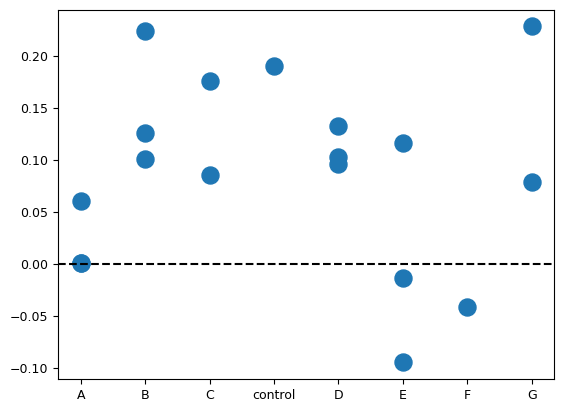

In [34]:
corr = pairwise_HKE_Pi_correlation(smoothed_hke, momentum_transfer.abs(), method="spearman")
plt.scatter(corr.index.get_level_values(0), corr, s=150)
plt.gca().axhline(0, color="k", ls="--")

In [35]:
region_categorization = pd.read_csv("../../derived_data/rcm_infos.csv", index_col=0)
region_categorization

,lon,lat,rounded depth,rounded mab,name,region id,region,color
index,,,,,,,,
0,-52.2870,-63.4032,299,343,A,0.0,shelf,#b7b38b
1,-52.2870,-63.4032,505,137,A,0.0,shelf,#b7b38b
2,-52.2870,-63.4032,614,28,A,0.0,shelf,#b7b38b
3,-51.6357,-63.5145,1318,338,B,1.0,open ocean,#3f8f6e
4,-51.6357,-63.5145,1513,143,B,2.0,IL,#145867
5,-51.6357,-63.5145,1625,31,B,3.0,BL,#221b38
6,-50.8113,-63.6560,2143,350,C,1.0,open ocean,#3f8f6e
7,-50.8113,-63.6560,2350,143,C,2.0,IL,#145867
8,-50.0897,-63.7783,2400,357,D,1.0,open ocean,#3f8f6e


In [36]:
def get_region_color(name, col, categorization):
    color_match = categorization.loc[
        (categorization["name"] == name) & (categorization["rounded depth"] == int(col)), "color"
    ]
    if not color_match.empty:
        color = color_match.iloc[0]  # Extract the first match
    else:
        color = "xkcd:rose"
    return color


color_list = []
mooring_index = []
for mooring, depth in corr.index:
    color_list.append(get_region_color(mooring, depth, region_categorization))
    if mooring == "control":
        mooring_index.append("C")
    else:
        mooring_index.append(mooring)


def custom_colorbar(figure, axis):
    color_dict = src.plots.get_region_color_dict(linebreak=True)
    color_dict.pop("air")
    color_dict["control"] = "xkcd:rose"
    cmap = mcolors.ListedColormap(color_dict.values())
    mappable = mpl.cm.ScalarMappable(norm=mcolors.Normalize(-0.5, 4.5), cmap=cmap)
    colorbar = figure.colorbar(mappable, ax=axis, orientation="vertical")
    colorbar.set_ticks(ticks=np.arange(len(color_dict.keys())), labels=list(color_dict.keys()))
    colorbar.ax.invert_yaxis()
    return colorbar

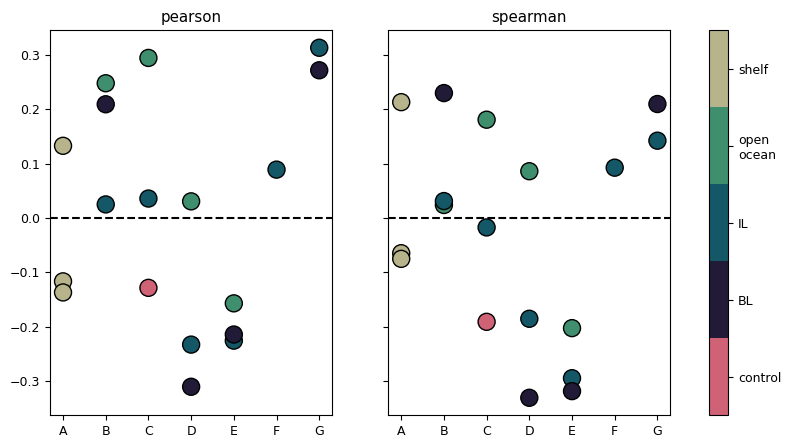

In [37]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
corr_pearson = pairwise_HKE_Pi_correlation(smoothed_hke, energy_transfer, method="pearson")
axes[0].scatter(mooring_index, corr_pearson, c=color_list, s=150, edgecolor="k")
axes[0].set_title("pearson")
corr_spearman = pairwise_HKE_Pi_correlation(smoothed_hke, energy_transfer, method="spearman")
axes[1].scatter(mooring_index, corr_spearman, c=color_list, s=150, edgecolor="k")
axes[1].set_title("spearman")
for ax in axes:
    ax.axhline(0, color="k", ls="--")
custom_colorbar(fig, axes)

In [38]:
corr_spearman

A        299     0.213297
         505    -0.064630
         614    -0.075012
B        1318    0.024081
         1513    0.031311
         1625    0.229998
C        2143    0.181036
         2350   -0.017197
control  750    -0.190844
D        2400    0.086218
         2615   -0.185263
         2724   -0.330617
E        3036   -0.202482
         3299   -0.294600
         3358   -0.318389
F        3835    0.092735
G        4120    0.142421
         4160    0.209861
dtype: float64

Text(0, 0.5, 'Spearman correlation\n($\\hat{\\mathcal{U}}(t)$, $𝛱(t)$)')

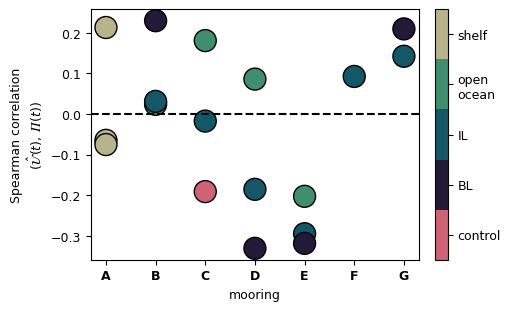

In [39]:
fig, ax = plt.subplots(1, figsize=(5, 3), sharex=True, sharey=True, layout="constrained")
corr_spearman = pairwise_HKE_Pi_correlation(smoothed_hke, energy_transfer, method="spearman")
ax.scatter(mooring_index, corr_spearman, c=color_list, s=250, edgecolor="k", alpha=1)
ax.axhline(0, color="k", ls="--")
custom_colorbar(fig, ax)
ax.set_xlabel("mooring")
xticks = ax.get_xticks()
labels = ax.get_xticklabels()
ax.set_xticks(ticks=xticks, labels=labels, fontweight="bold")
ax.set_ylabel("Spearman correlation\n($\\hat{\\mathcal{U}}(t)$, $𝛱(t)$)")
# wave field energy - energy transfer
# fig.savefig("./atmosphere_wave_field_correlation.pdf")

Text(0, 0.5, 'Spearman correlation\n($\\hat{\\mathcal{U}}(t)$, $𝛱(t)$)')

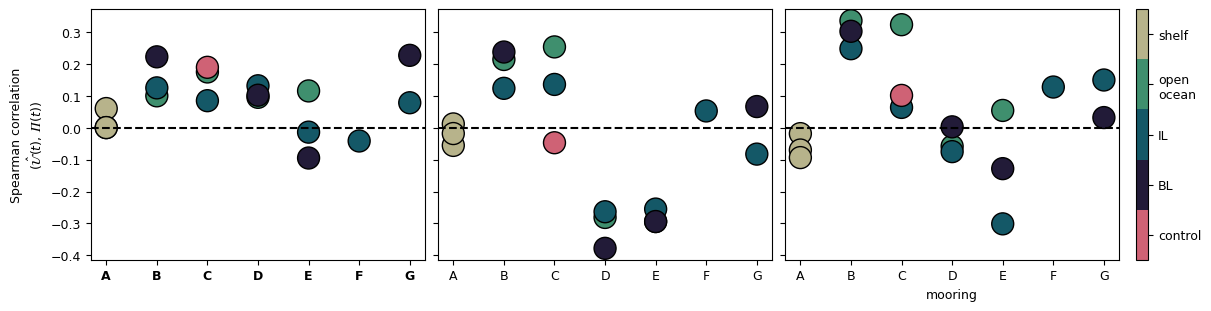

In [40]:
fig, axis = plt.subplots(ncols=3, figsize=(12, 3), sharex=True, sharey=True, layout="constrained")

stresses = [
    momentum_transfer.abs(),
    pd.DataFrame(
        index=momentum_transfer.index,
        columns=momentum_transfer.columns,
        data=momentum_transfer.values.imag,
    ),
    pd.DataFrame(
        index=momentum_transfer.index,
        columns=momentum_transfer.columns,
        data=momentum_transfer.values.real,
    ),
]
for ax, series in zip(axis, stresses):
    corr_spearman = pairwise_HKE_Pi_correlation(smoothed_hke, series, method="spearman")
    ax.scatter(mooring_index, corr_spearman, c=color_list, s=250, edgecolor="k", alpha=1)
    ax.axhline(0, color="k", ls="--")

custom_colorbar(fig, axis[2])
ax.set_xlabel("mooring")
xticks = ax.get_xticks()
labels = ax.get_xticklabels()
axis[0].set_xticks(ticks=xticks, labels=labels, fontweight="bold")
axis[0].set_ylabel("Spearman correlation\n($\\hat{\\mathcal{U}}(t)$, $𝛱(t)$)")
# wave field energy - energy transfer
# fig.savefig("./atmosphere_wave_field_correlation.pdf")

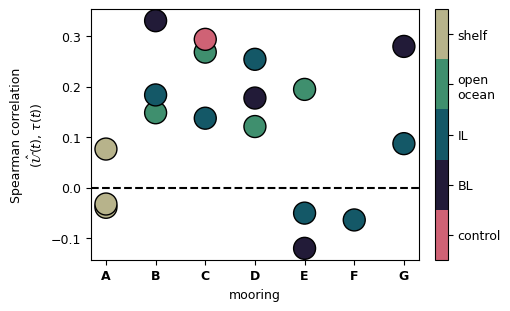

In [41]:
fig, ax = plt.subplots(1, figsize=(5, 3), sharex=True, sharey=True, layout="constrained")
corr_spearman = pairwise_HKE_Pi_correlation(
    smoothed_hke, momentum_transfer.abs().apply(smooth, args=(5,)), method="spearman"
)
ax.scatter(mooring_index, corr_spearman, c=color_list, s=250, edgecolor="k", alpha=1)
ax.axhline(0, color="k", ls="--")
custom_colorbar(fig, ax)
ax.set_xlabel("mooring")
xticks = ax.get_xticks()
labels = ax.get_xticklabels()
ax.set_xticks(ticks=xticks, labels=labels, fontweight="bold")
ax.set_ylabel("Spearman correlation\n($\\hat{\\mathcal{U}}(t)$, $\\tau(t)$)")
# wave field energy - energy transfer
fig.savefig("./windstress_wave_field_correlation.pdf")

In [42]:
smooth(momentum_transfer["C"].abs(), 5)

array([0.03446666, 0.03124208, 0.03258105, 0.02775504, 0.01327536,
       0.02818719, 0.07534054, 0.10257588, 0.08566462, 0.05674234,
       0.04157727, 0.05137342, 0.05547328, 0.03100405, 0.01239057,
       0.01879301, 0.02556301, 0.01502993, 0.00437983, 0.0043385 ,
       0.02056475, 0.03622743, 0.02566821, 0.02798363, 0.04095406,
       0.02953663, 0.0382009 , 0.05586698, 0.04324346, 0.02884248,
       0.01462313, 0.00553957, 0.00967   , 0.01218039, 0.01566507,
       0.02134243, 0.01896416, 0.02189475, 0.07864395, 0.13013563,
       0.09987128, 0.05357316, 0.03314384, 0.06198435, 0.09294814,
       0.05168299, 0.0312035 , 0.06083565, 0.0788294 , 0.0825367 ,
       0.06978593, 0.07367524, 0.09854409, 0.07779768, 0.0302914 ,
       0.01279314, 0.0151132 , 0.01791744, 0.0256056 , 0.03104996,
       0.03068924, 0.03360627, 0.02275842, 0.02065354, 0.03388228,
       0.02387627, 0.00764518, 0.0032597 , 0.00420867, 0.0063799 ,
       0.00598503, 0.00697122, 0.0084266 , 0.00702105, 0.00691

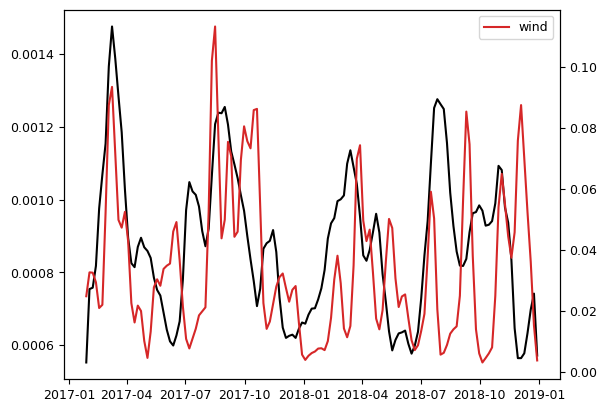

In [43]:
def smoothed(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    new = signal.convolve(array.values.flatten(), window, mode="same") / np.sum(
        window
    )  # smooth by convolving speed with window
    return pd.Series(index=array.index, data=new)


def prepare_pair_of_time_series(tau, hke):
    assert np.all(tau.index == hke.index)
    pair = pd.DataFrame(index=tau.index, data={"tau": tau, "hke": hke})
    pair.dropna(how="any", axis="index", inplace=True)
    return pair


pair = prepare_pair_of_time_series(
    tau=smoothed(momentum_transfer["C"].abs(), 6), hke=smoothed_hke["C", "2350"]
)
# pair = prepare_pair_of_time_series(tau=smoothed(momentum_transfer["A"].abs(),10),hke=smoothed_hke["A", "614"])

line1 = plt.plot(pair.index, pair["hke"], "k", label="hke")
ax2 = plt.gca().twinx()
line2 = ax2.plot(pair.index, pair["tau"], "tab:red", label="wind")
plt.legend()

Text(0, 0.5, 'max corr($\\tau$,HKE) / %')

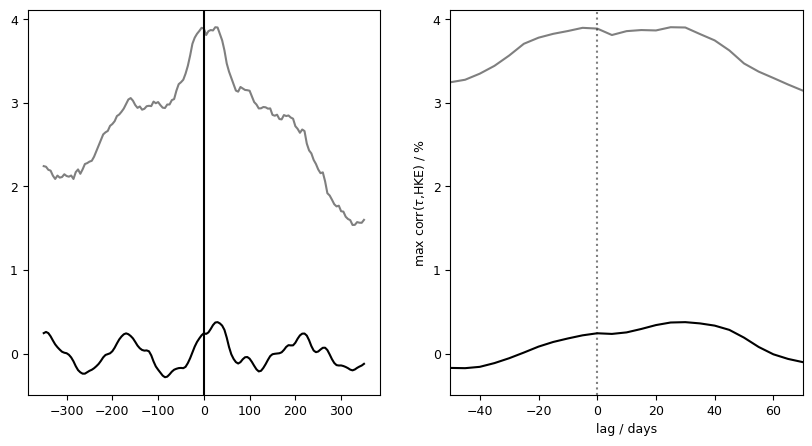

In [44]:
corr = signal.correlate(
    (pair["tau"] - pair["tau"].mean()) / pair["tau"].std(),
    (pair["hke"] - pair["hke"].mean()) / pair["hke"].std(),
    mode="same",
) / len(pair["tau"])
corr_tau_HKE = corr  # /np.nanmax(corr) * 100
lags_tau_HKE = signal.correlation_lags(len(pair["tau"]), len(pair["hke"]), mode="same")

corr2 = signal.correlate(
    momentum_transfer["C"].abs() / momentum_transfer["C"].abs().std(),
    hke["C", "2350"] / hke["C", "2350"].std(),
    mode="same",
) / len(momentum_transfer["C"])
corr2_in_percent = corr2  # /np.nanmax(corr2) * 100
lags2 = signal.correlation_lags(len(momentum_transfer["C"]), len(hke["C", "2350"]), mode="same")

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].axvline(0, color="k")
ax[0].plot(5 * lags_tau_HKE, corr_tau_HKE, "k")
ax[0].plot(5 * lags2, corr2_in_percent, "k", alpha=0.5)

ax[1].axvline(0, color="k", alpha=0.5, ls=":")
ax[1].plot(5 * lags_tau_HKE, corr_tau_HKE, "k")
ax[1].plot(5 * lags2, corr2_in_percent, "k", alpha=0.5)
ax[1].set_xlim(-50, 70)
# ax[1].set_ylim(81,101)
ax[1].set_xlabel("lag / days")
ax[1].set_ylabel("max corr($\\tau$,HKE) / %")

In [45]:
pair

,tau,hke
Unnamed: 0,,
2017-01-28,0.024734,0.000552
2017-02-02,0.032556,0.000754
2017-02-07,0.032450,0.000758
2017-02-12,0.029304,0.000818
2017-02-17,0.020870,0.000976
...,...,...
2018-12-09,0.069737,0.000577
2018-12-14,0.052236,0.000633
2018-12-19,0.036058,0.000697


0.034343638444813834 0.0008798268983789284


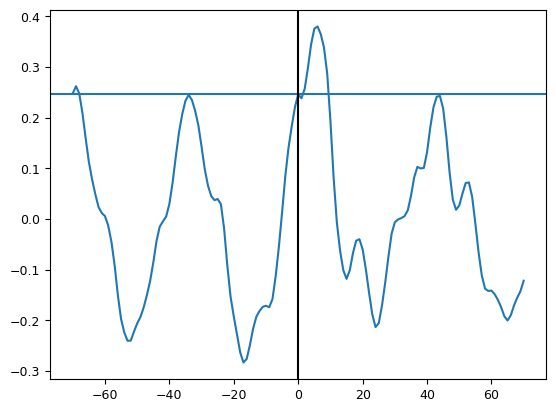

In [46]:
def plot_xcorr(x, y, ax):
    "Plot cross-correlation (same) between two signals."
    N = max(len(x), len(y))
    n = min(len(x), len(y))

    lags = signal.correlation_lags(len(x), len(y), mode="same")
    c = signal.correlate(x / np.std(x), y / np.std(y), "same")
    print(x.mean(), y.mean())
    c = signal.correlate(x - x.mean(), y - y.mean(), "same") / (np.std(x * np.std(y)))

    ax.plot(lags, c / n)


_, ax = plt.subplots(1)
plot_xcorr(pair["tau"], pair["hke"], ax)
ax.axhline(pair["tau"].corr(pair["hke"]))
ax.axvline(0, color="k")

<Axes: xlabel='Unnamed: 0'>

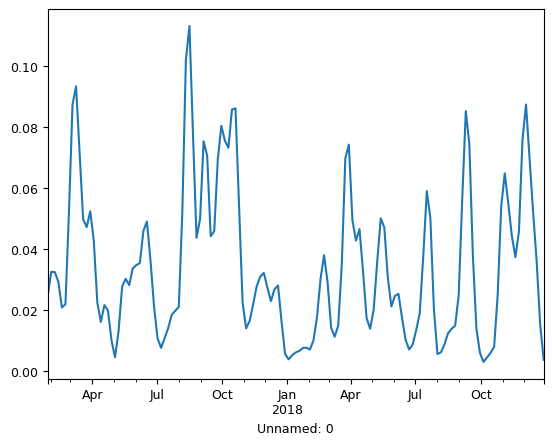

In [47]:
pair["tau"].plot()

The x-axis describes the lag of y to x.  
x = windstress  
y = HKE  
Positive lag → x leads y (i.e., x happens first)  
Negative lag → y leads x

Text(0, 0.5, 'normalized\ncross-correlation\n($|\\tau| \\star \\text{HKE}$) / (1)')

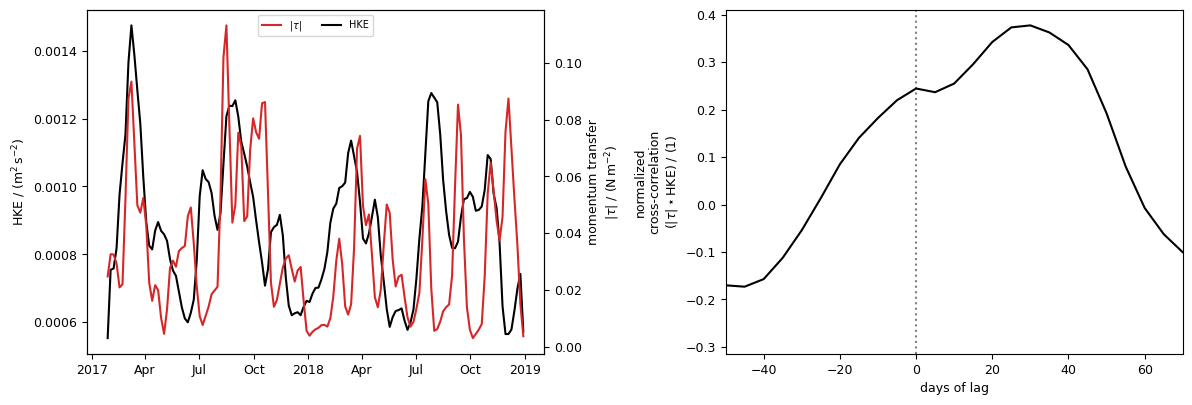

In [48]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

fig, ax = plt.subplots(ncols=2, figsize=(30 * cm, 10 * cm), layout="constrained")

# +pd.Timedelta(days=30)

line1 = ax[0].plot(
    pair.index,
    pair["hke"],
    "k",
    label="HKE",
)  # momentum_transfer["C"].abs(), hke["C","2350"]
# ax[0].plot(hke["C","2350"].index, hke["C","2350"], "k", alpha=0.3, lw=0.7)
ax[0].set_ylabel(r"HKE / (m$^2\,$s$^{-2}$)")
twinx = ax[0].twinx()
twinx.set_ylabel("momentum transfer\n$|\\tau|$ / (N$\\,$m$^{-2}$)")
line2 = twinx.plot(pair.index, pair["tau"], "tab:red", label="$|\\tau|$")
# twinx.plot(momentum_transfer.index, momentum_transfer["C"].abs(), color="tab:red", alpha = 0.4) #, label="$|\\tau|$")
locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax[0].xaxis.set_major_locator(locator)
ax[0].xaxis.set_major_formatter(formatter)
# added these three lines
lns = line2 + line1
labs = [l.get_label() for l in lns]
ax[0].legend(lns, labs, ncols=2, loc="upper center", fontsize=7)

ax[1].axvline(0, color="k", alpha=0.5, ls=":")
ax[1].plot(5 * lags_tau_HKE, corr_tau_HKE, "k", label="smoothed")
# ax[1].plot(5*lags2,corr2_in_percent, "k", alpha = 0.3, label="raw", lw=0.7)
ax[1].set_xlim(-50, 70)
# ax[1].set_ylim(81,101)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation\n($|\\tau| \\star \\text{HKE}$) / (1)")
# ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

In [49]:
pair["tau"].corr(pair["hke"])

np.float64(0.24610086076496906)

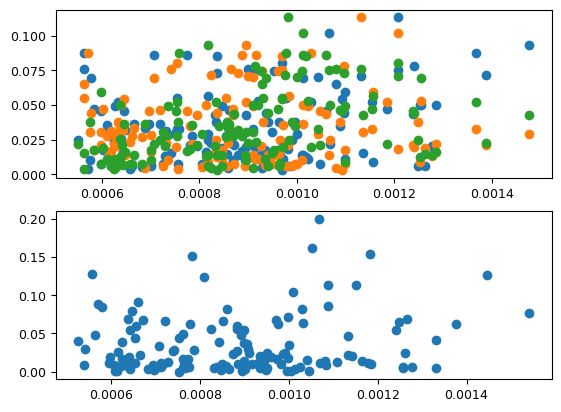

In [50]:
fig, ax = plt.subplots(2)
ax[0].scatter(pair["hke"], pair["tau"])
ax[0].scatter(pair["hke"][5:], pair["tau"][:-5])
ax[0].scatter(pair["hke"][:-5], pair["tau"][5:])
ax[1].scatter(hke["C", "2350"], momentum_transfer["C"].abs())

# Extended correlations

In [51]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    for i, col in enumerate(df.columns):
        # basically, if column is complex
        if not is_numeric_dtype(df[col]):
            df[col] = df[col].apply(lambda x: complex(x))
    df = df.fillna(0)
    return df


def read_csv(path):
    csv = pd.read_csv(path)
    return clean_csv(csv)

In [52]:
velocity = pd.read_csv("../../derived_data/velo_at_C.csv")
velocity.set_index(pd.to_datetime(velocity["time_2350"]), inplace=True)
velocity.drop("time_2350", inplace=True, axis="columns")
velocity["2350"] = velocity["2350"].apply(lambda x: complex(x))
velocity

,2350
time_2350,
2017-01-26 11:49:59.999996,-0.0086+0.0537j
2017-01-26 13:49:59.999999,-0.0475+0.0206j
2017-01-26 15:50:00.000002,-0.0440-0.0151j
2017-01-26 17:49:59.999996,-0.0473-0.0209j
2017-01-26 19:49:59.999999,0.0045+0.0436j
...,...
2019-01-29 01:49:59.999999,-0.0080+0.0617j
2019-01-29 03:50:00.000002,-0.0063+0.0487j
2019-01-29 05:49:59.999996,0.0385+0.0261j


/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/pandas/core/window/rolling.py:371: ComplexWarning: Casting complex values to real discards the imaginary part
  values = ensure_float64(values)


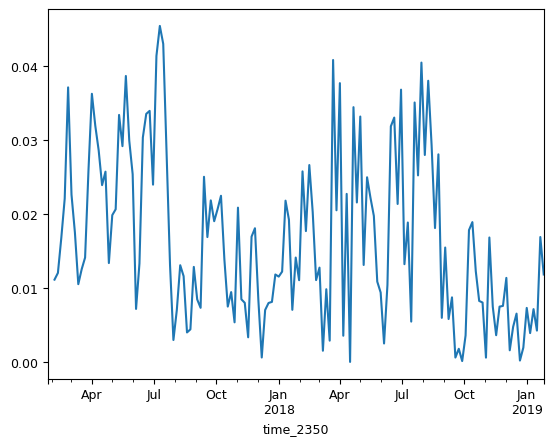

In [53]:
# daily_real = pd.Series(index=velocity.index, data=velocity["2350"].values.imag).resample("1D").mean()
daily_imag = (
    pd.Series(index=velocity.index, data=velocity["2350"].values)
    .resample("5D")
    .mean()
    .rolling(3)
    .mean()
    .abs()
    .plot()
)

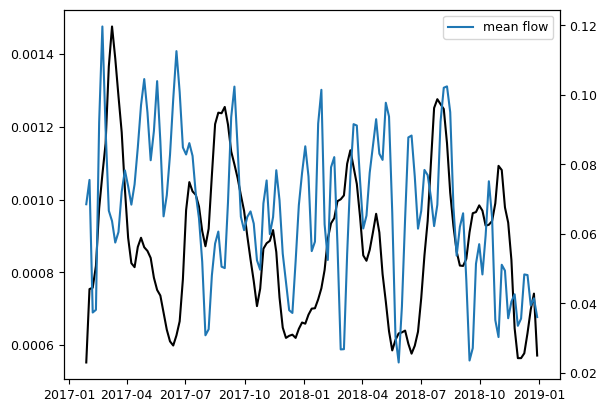

In [54]:
def prepare_pair_of_time_series(a, b, label_a="mean_flow", label_b="hke"):
    assert np.all(a.index == b.index)
    pair = pd.DataFrame(
        index=a.index, data={label_a: a.values.flatten(), label_b: b.values.flatten()}
    )
    pair.dropna(how="any", axis="index", inplace=True)
    return pair


truncated_mean_flow = (
    velocity.resample("5D", origin=smoothed_hke.index[0])
    .mean()
    .abs()
    .loc[smoothed_hke.index[0] : smoothed_hke.index[-1]]
)
truncated_mean_flow = pd.Series(
    index=truncated_mean_flow.index, data=truncated_mean_flow["2350"].values
)
truncated_mean_flow = smoothed(truncated_mean_flow, 5)

pair_veloHKE = prepare_pair_of_time_series(a=truncated_mean_flow, b=smoothed_hke["C", "2350"])
# pair = prepare_pair_of_time_series(tau=smoothed(momentum_transfer["A"].abs(),10),hke=smoothed_hke["A", "614"])

line1 = plt.plot(pair.index, pair_veloHKE["hke"], "k", label="hke")
ax2 = plt.gca().twinx()
line2 = ax2.plot(pair.index, pair_veloHKE["mean_flow"], "tab:blue", label="mean flow")
plt.legend()

0.06690498262513764 0.0008798268983789284


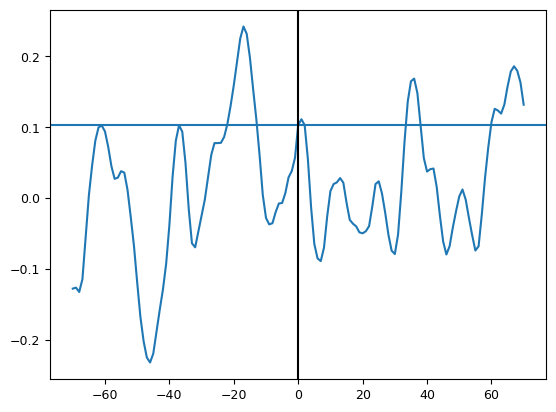

In [55]:
def plot_xcorr(x, y, ax):
    "Plot cross-correlation (same) between two signals."
    N = max(len(x), len(y))
    n = min(len(x), len(y))

    lags = signal.correlation_lags(len(x), len(y), mode="same")
    # c = signal.correlate(x / np.std(x), y / np.std(y), 'same')
    print(x.mean(), y.mean())
    c = signal.correlate(x - x.mean(), y - y.mean(), "same") / (np.std(x * np.std(y)))

    ax.plot(lags, c / n)
    return lags, c / n


_, ax = plt.subplots(1)
lags_mean_flow_HKE, corr_mean_flow_HKE = plot_xcorr(
    pair_veloHKE["mean_flow"], pair_veloHKE["hke"], ax
)
ax.axhline(pair_veloHKE["mean_flow"].corr(pair_veloHKE["hke"]))
ax.axvline(0, color="k")

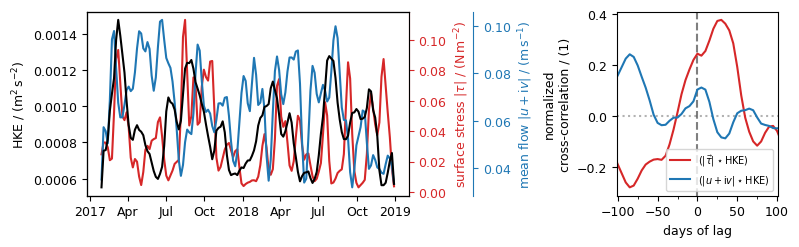

In [56]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

# fig, ax = plt.subplots(nrows=2, figsize=(18*cm, 12*cm),layout="constrained")
fig, ax = plt.subplots(
    ncols=2, figsize=(20 * cm, 6 * cm), layout="constrained", width_ratios=[2, 1]
)

line1 = ax[0].plot(
    pair.index,
    pair["hke"],
    "k",
    label="HKE",
    lw=1.5,
)  # momentum_transfer["C"].abs(), hke["C","2350"]
# ax[0].plot(hke["C","2350"].index, hke["C","2350"], "k", alpha=0.3, lw=0.7)
ax[0].set_ylabel(r"HKE / (m$^2\,$s$^{-2}$)")
twinx = ax[0].twinx()
twinx.set_ylabel("surface stress $|\\tau|$ / (N$\\,$m$^{-2}$)")
line2 = twinx.plot(
    pair.index,
    pair["tau"],
    "tab:red",
    label="$|\\tau|$",
    lw=1.5,
)
# twinx.plot(momentum_transfer.index, momentum_transfer["C"].abs(), color="tab:red", alpha = 0.4) #, label="$|\\tau|$")
twinx.spines["right"].set_color("tab:red")
twinx.tick_params(axis="y", colors="tab:red")
twinx.yaxis.label.set_color("tab:red")

twinx2 = ax[0].twinx()
smoothed_truncated_mean_flow = smoothed(truncated_mean_flow, 6)
# twinx2.set_ylim(0.04,np.max(smoothed_truncated_mean_flow)*1.1)
twinx2.set_ylabel(r"mean flow $|u + $i$v|$ / (m$\,$s$^{-1}$)")
twinx2.spines["right"].set_position(("axes", 1.2))  # shift by 10% of the figure width
twinx2.spines["right"].set_color("tab:blue")
twinx2.tick_params(axis="y", colors="tab:blue")
twinx2.yaxis.label.set_color("tab:blue")

line3 = twinx2.plot(
    smoothed_truncated_mean_flow.index,
    smoothed_truncated_mean_flow,
    color="tab:blue",
    alpha=1,
    lw=1.5,
    label="mean flow",
)  # , label="$|\\tau|$")

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax[0].xaxis.set_major_locator(locator)
ax[0].xaxis.set_major_formatter(formatter)
ax[0].set_facecolor("None")
ax[0].set_zorder(10)
# # added these three lines
# lns = line3+line2+line1
# labs = [l.get_label() for l in lns]
# ax[0].legend(lns, labs, ncols=3, loc="upper center", fontsize=7)

# ax[1].grid()
ax[1].axhline(0, color="k", alpha=0.3, ls=":")
ax[1].axvline(0, color="k", alpha=0.5, ls="--")

ax[1].xaxis.set_major_locator(mticker.FixedLocator(np.arange(-100, 150, 50)))
ax[1].xaxis.set_minor_locator(mticker.FixedLocator(np.arange(-100, 110, 25)))
ax[1].plot(5 * lags_tau_HKE, corr_tau_HKE, "tab:red", label="($|\\vec{\\tau}| \\star \\text{HKE}$)")
ax[1].plot(
    5 * lags_mean_flow_HKE,
    corr_mean_flow_HKE,
    "tab:blue",
    label="($|u + $i$v| \\star \\text{HKE}$)",
)
# ax[1].plot(5*lags2,corr2_in_percent, "k", alpha = 0.3, label="raw", lw=0.7)
# ax[1].set_xlim(-50,70)
ax[1].set_xlim(-55, 70)
ax[1].set_xlim(-101, 101)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation / (1)")
# ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax[1].legend(fontsize=7)
fig.savefig("wind_hke_lag.pdf")

In [57]:
nsquared = read_csv("../../derived_data/N2_at_C_2350m.csv")
nsquared
# nsquared["2350"] = np.array(nsquared["2350"].values)

,2350
Unnamed: 0,
2017-01-26,0.000002
2017-01-27,0.000002
2017-01-28,0.000001
2017-01-29,0.000003
2017-01-30,0.000002
...,...
2019-01-25,0.000003
2019-01-26,0.000003
2019-01-27,0.000002


,2350
Unnamed: 0,
2017-01-28,0.000002
2017-02-02,0.000002
2017-02-07,0.000002
2017-02-12,0.000002
2017-02-17,0.000002
...,...
2018-12-09,0.000002
2018-12-14,0.000002
2018-12-19,0.000002


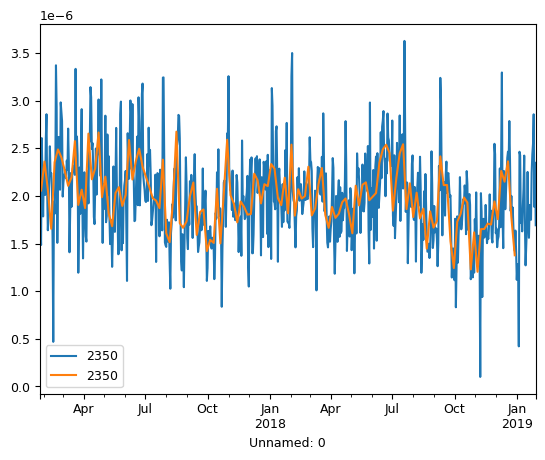

In [58]:
_, ax = plt.subplots()
nsquared.plot(ax=ax)
truncated_nsquared = (
    nsquared.resample("5D", origin=smoothed_hke.index[0])
    .mean()
    .loc[smoothed_hke.index[0] : smoothed_hke.index[-1]]
)
truncated_nsquared.plot(ax=ax)
truncated_nsquared

1.991190308760785e-06 0.0008798268983789284


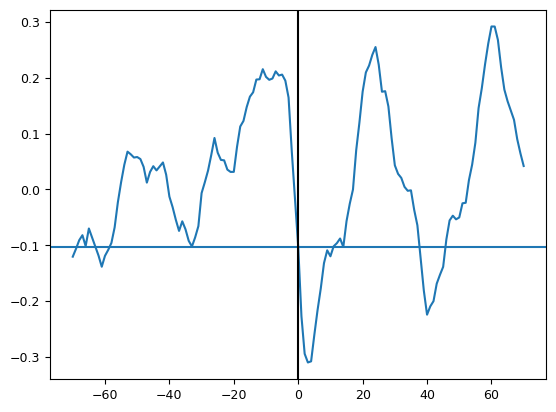

In [59]:
_, ax = plt.subplots(1)

pair_N2_HKE = prepare_pair_of_time_series(
    truncated_nsquared, smoothed_hke["C", "2350"], "nsquared", "hke"
)
lags_N2_HKE, corr_N2_HKE = plot_xcorr(pair_N2_HKE["nsquared"], pair_N2_HKE["hke"], ax)
ax.axhline(pair_N2_HKE["nsquared"].corr(pair_N2_HKE["hke"]))
ax.axvline(0, color="k")

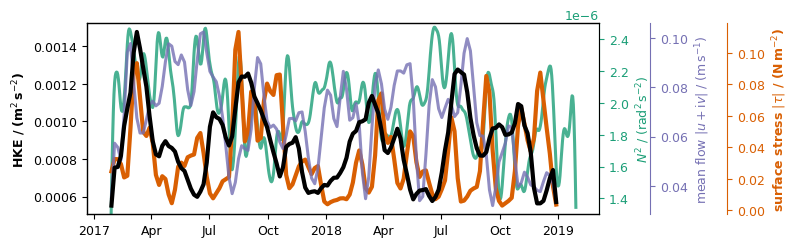

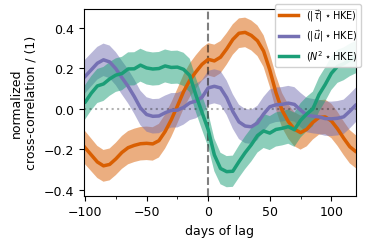

In [60]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

# fig, ax = plt.subplots(nrows=2, figsize=(18*cm, 12*cm),layout="constrained")
fig, ax = plt.subplots(
    ncols=1, figsize=(20 * cm, 6 * cm), layout="constrained"
)  # ,width_ratios=[2,1])
ax = [ax]

line1 = ax[0].plot(
    pair.index,
    pair["hke"],
    "k",
    label="HKE",
    lw=3,
)  # momentum_transfer["C"].abs(), hke["C","2350"]
# ax[0].plot(hke["C","2350"].index, hke["C","2350"], "k", alpha=0.3, lw=0.7)
ax[0].set_ylabel(r"HKE / (m$^2\,$s$^{-2}$)", fontweight="bold")

twinx3 = ax[0].twinx()
twinx3.set_ylabel(r"$N^2$ / (rad$^2\,$s$^{-2}$)")
# twinx3.spines['right'].set_position(('axes', 1.4)) # shift by 10% of the figure width
twinx3.spines["right"].set_color("#1b9e77")
twinx3.set_ylim(1.3e-6, 2.5e-6)
# twinx2.set_ylim(0.04,np.max(smoothed_truncated_mean_flow)*1.1)
twinx3.tick_params(axis="y", colors="#1b9e77")
twinx3.yaxis.label.set_color("#1b9e77")
line4 = twinx3.plot(
    nsquared.index, smoothed(nsquared, 20), color="#1b9e77", alpha=0.8, lw=2.2, label="$N^2"
)  # , label="$|\\tau|$")

twinx = ax[0].twinx()
twinx.spines["right"].set_position(("axes", 1.25))
twinx.set_ylabel("surface stress $|\\tau|$ / (N$\\,$m$^{-2}$)", fontweight="bold")
line2 = twinx.plot(pair.index, pair["tau"], "#d95f02", label="$|\\tau|$", lw=3)
# twinx.plot(momentum_transfer.index, momentum_transfer["C"].abs(), color="#d95f02", alpha = 0.4) #, label="$|\\tau|$")
twinx.spines["right"].set_color("#d95f02")
twinx.tick_params(axis="y", colors="#d95f02")
twinx.yaxis.label.set_color("#d95f02")

twinx2 = ax[0].twinx()
twinx2.set_ylabel(r"mean flow $|u + $i$v|$ / (m$\,$s$^{-1}$)")
twinx2.spines["right"].set_position(("axes", 1.1))  # shift by 10% of the figure width
twinx2.spines["right"].set_color("#7570b3")
smoothed_truncated_mean_flow = smoothed(truncated_mean_flow, 6)
# twinx2.set_ylim(0.04,np.max(smoothed_truncated_mean_flow)*1.1)
twinx2.tick_params(axis="y", colors="#7570b3")
twinx2.yaxis.label.set_color("#7570b3")

line3 = twinx2.plot(
    smoothed_truncated_mean_flow.index,
    smoothed_truncated_mean_flow,
    color="#7570b3",
    alpha=0.8,
    lw=2.2,
    label="mean flow",
)  # , label="$|\\tau|$")


locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax[0].xaxis.set_major_locator(locator)
ax[0].xaxis.set_major_formatter(formatter)
ax[0].set_facecolor("None")
ax[0].set_zorder(10)
# # added these three lines
# lns = line3+line2+line1
# labs = [l.get_label() for l in lns]
# ax[0].legend(lns, labs, ncols=3, loc="upper center", fontsize=7)
fig.savefig("surface_hke.pdf")

fig, ax = plt.subplots(ncols=1, figsize=(9 * cm, 6 * cm), layout="constrained")
ax = ["", ax]
ax[1].axhline(0, color="k", alpha=0.3, ls=":")
ax[1].axvline(0, color="k", alpha=0.5, ls="--")

ax[1].xaxis.set_major_locator(mticker.FixedLocator(np.arange(-100, 150, 50)))
ax[1].xaxis.set_minor_locator(mticker.FixedLocator(np.arange(-100, 110, 25)))


def plot_standard_error(x, y, N, axis, color, alpha):
    # standard error of pearson correlation according to Bonett2008, recommended in Gnambs2023
    standard_error = (1 - y**2) / np.sqrt(N - 3)
    axis.fill_between(
        x, y - standard_error, y + standard_error, color=color, alpha=alpha, edgecolor=None
    )


plot_standard_error(
    x=5 * lags_tau_HKE, y=corr_tau_HKE, N=len(pair["hke"]), axis=ax[1], color="#d95f02", alpha=0.5
)
ax[1].plot(
    5 * lags_tau_HKE, corr_tau_HKE, "#d95f02", label="($|\\vec{\\tau}| \\star \\text{HKE}$)", lw=2.5
)

# standard_error_tau_HKE = (1-corr_tau_HKE**2)/np.sqrt(len(pair["hke"]))
# ax[1].fill_between(5*lags_tau_HKE,corr_tau_HKE-standard_error_tau_HKE,corr_tau_HKE+standard_error_tau_HKE, ax[1]color="#d95f02", alpha=0.7)

plot_standard_error(
    x=5 * lags_mean_flow_HKE,
    y=corr_mean_flow_HKE,
    N=len(pair["hke"]),
    axis=ax[1],
    color="#7570b3",
    alpha=0.5,
)
ax[1].plot(
    5 * lags_mean_flow_HKE,
    corr_mean_flow_HKE,
    "#7570b3",
    label="($|\\vec{u}| \\star \\text{HKE}$)",
    lw=2.5,
)

# standard_error_mean_flow_HKE = (1-corr_mean_flow_HKE**2)/np.sqrt(len(pair["hke"]))
# ax[1].fill_between(5*lags_tau_HKE,corr_mean_flow_HKE-standard_error_mean_flow_HKE,corr_mean_flow_HKE+standard_error_mean_flow_HKE, color="#7570b3", alpha=0.7)

plot_standard_error(
    x=5 * lags_N2_HKE, y=corr_N2_HKE, N=len(pair["hke"]), axis=ax[1], color="#1b9e77", alpha=0.5
)
ax[1].plot(5 * lags_N2_HKE, corr_N2_HKE, "#1b9e77", label="($N^2 \\star \\text{HKE}$)", lw=2.5)

# standard_error_tau_HKE = (1-corr_tau_HKE**2)/np.sqrt(len(pair["hke"]))
# ax[1].fill_between(5*lags_tau_HKE,corr_tau_HKE-standard_error_tau_HKE,corr_tau_HKE+standard_error_tau_HKE, color="#1b9e77", alpha=0.7)

# ax[1].plot(5*lags2,corr2_in_percent, "k", alpha = 0.3, label="raw", lw=0.7)
# ax[1].set_xlim(-50,70)
ax[1].set_xlim(-55, 70)
ax[1].set_xlim(-101, 120)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation / (1)")
# ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.legend(fontsize=7, loc="upper right", framealpha=0.9)
fig.savefig("surface_hke_corr.pdf")

In [61]:
from matplotlib.collections import PolyCollection

# import matplotlib


def plot_xy_errorbands(
    x,
    y,
    x_errors,
    y_errors,
    x_style: dict = {},
    y_style: dict = {},
    x_label: str = "",
    y_label: str = "",
    plot_errorbars: bool = False,
    ax: mpl.axes.Axes = None,
):

    x_lower = x - x_errors
    x_upper = x + x_errors
    y_lower = y - y_errors
    y_upper = y + y_errors

    if ax is None:
        fig, ax = plt.subplots(1)

    if plot_errorbars:
        ax.errorbar(
            x,
            y,
            xerr=x_errors,
            yerr=y_errors,
            fmt="o",
            linestyle="None",
            color=x_style["edgecolor"],
            label="points",
        )

    # Build a list of quads between consecutive points
    verts = [
        [
            (x_upper[i], y[i]),
            (x_upper[i + 1], y[i + 1]),
            (x_lower[i + 1], y[i + 1]),
            (x_lower[i], y[i]),
        ]
        for i in range(len(x) - 1)
    ]

    # verts = [
    #     [(x_upper[i], y[i]),
    #     (x[i+1], y_lower[i+1]),
    #     (x_upper[i+1], y[i+1]),
    #     (x[i+1], y_upper[i+1]),
    #     (x_lower[i+1], y[i+1]),
    #     (x[i], y_upper[i]),
    #     (x_lower[i], y[i]),
    #     (x[i], y_lower[i])]
    #     for i in range(len(x)-1)
    # ]
    # unique_verts
    # for vert in verts:
    # unique = np.array(list({tuple(a) for a in arr}))

    poly = PolyCollection(
        verts, **x_style
    )  # facecolors=["seagreen"], alpha=0.3, edgecolors="none")
    ax.add_collection(poly)

    ax.fill_between(x, y_lower, y_upper, **y_style, label=y_label)

1.722168798024673e-09 0.0008839987059892515


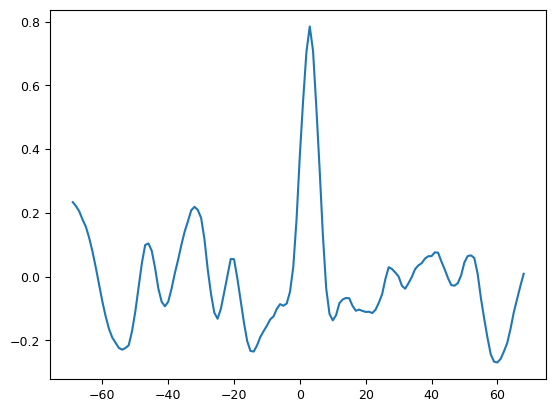

In [62]:
dissip_IGW_at_C = pd.read_csv(
    "../../derived_data/wave_induced_dissipation_rate_time_series_at_C.csv"
)
dissip_IGW_at_C.set_index(pd.to_datetime(dissip_IGW_at_C["Unnamed: 0"]), inplace=True)
dissip_IGW_at_C.drop("Unnamed: 0", inplace=True, axis="columns")
# dissip_IGW_at_C
dissip_hke_pair = prepare_pair_of_time_series(
    dissip_IGW_at_C.iloc[:-3], smoothed_hke["C", "2350"].iloc[3:], "dissip", "hke"
)
_, ax = plt.subplots(1)
lags_dissip_hke, corr_dissip_hke = plot_xcorr(
    dissip_hke_pair["dissip"], dissip_hke_pair["hke"], ax=ax
)

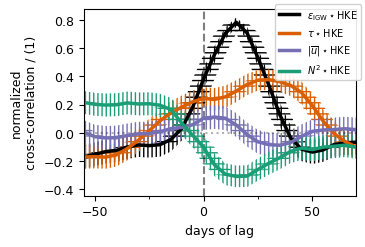

In [63]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

fig, ax = plt.subplots(ncols=1, figsize=(9 * cm, 6 * cm), layout="constrained")
ax = ["", ax]
ax[1].axhline(0, color="k", alpha=0.3, ls=":")
ax[1].axvline(0, color="k", alpha=0.5, ls="--")

ax[1].xaxis.set_major_locator(mticker.FixedLocator(np.arange(-100, 150, 50)))
ax[1].xaxis.set_minor_locator(mticker.FixedLocator(np.arange(-100, 110, 25)))


def get_standard_error(x, y, N):
    # standard error of pearson correlation according to Bonett2008, recommended in Gnambs2023
    standard_error = (1 - y**2) / np.sqrt(N - 3)
    return standard_error
    # axis.fill_between(x,y-standard_error,y+standard_error, color=color, alpha=alpha, edgecolor=None)


def plot_corr_with_error_bands(x, y, N, axis, label, color, plot_errorbars=False):

    y_style = {"hatch": "||||", "facecolor": "None", "linewidth": 0}
    x_style = {"hatch": "---", "facecolor": "None", "linewidth": 0}
    x_style["edgecolor"] = color
    y_style["edgecolor"] = color
    # x=5*lags_tau_HKE
    # y=corr_tau_HKE
    x_err = 5
    y_err = get_standard_error(x=x, y=y, N=N)
    plot_xy_errorbands(x, y, x_err, y_err, x_style, y_style, plot_errorbars=plot_errorbars, ax=axis)
    axis.plot(x, y, color=color, label=label, lw=2.5)


# plot_standard_error(x=5*lags_tau_HKE,y=corr_tau_HKE,N=len(pair["hke"]),axis=ax[1], color="#d95f02", alpha=0.5)
# y_style = {"hatch":"||||", "facecolor":"None", "linewidth":0}
# x_style = {"hatch":"---", "facecolor":"None", "linewidth":0}
# y_style = {"facecolor":"xkcd:pale green", "edgecolor":"k", "alpha":0.9, "linewidth":0}
# x_style = {"facecolor":"xkcd:pale green", "edgecolor":"k", "linewidth":0}

x = 5 * lags_dissip_hke
y = corr_dissip_hke
N = len(dissip_hke_pair["hke"])
label = "$\\varepsilon_\\mathrm{IGW} \\star \\text{HKE}$"
color = "k"
plot_corr_with_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

x = 5 * lags_tau_HKE
y = corr_tau_HKE
N = len(pair["hke"])
label = "$\\tau \\star \\text{HKE}$"
color = "#d95f02"
plot_corr_with_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

x = 5 * lags_mean_flow_HKE
y = corr_mean_flow_HKE
N = len(pair["hke"])
label = "$|\\overline{u}| \\star \\text{HKE}$"
color = "#7570b3"
plot_corr_with_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

x = 5 * lags_N2_HKE
y = corr_N2_HKE
N = len(pair["hke"])
label = "$N^2 \\star \\text{HKE}$"
color = "#1b9e77"
plot_corr_with_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)


# x_err = 5
# y_err = get_standard_error(x=5*lags_tau_HKE,y=corr_tau_HKE,)
# plot_xy_errorbands(x,y,x_err,y_err,x_style, y_style,plot_errorbars=True,ax=ax[1])
# ax[1].plot(x,y, "#d95f02", label="($|\\vec{\\tau}| \\star \\text{HKE}$)", lw=2.5)

# x_style["edgecolor"] = "#7570b3"
# y_style["edgecolor"] = "#7570b3"
# x=5*lags_mean_flow_HKE
# y=corr_mean_flow_HKE
# x_err = 5
# y_err = get_standard_error(x=5*lags_mean_flow_HKE,y=corr_tau_HKE,N=len(pair["hke"]))
# plot_xy_errorbands(x,y,x_err,y_err,x_style, y_style,plot_errorbars=True,ax=ax[1])
# ax[1].plot(5*lags_mean_flow_HKE, corr_mean_flow_HKE, "#7570b3", label="($|\\vec{u}| \\star \\text{HKE}$)", lw=2.5)

# # standard_error_mean_flow_HKE = (1-corr_mean_flow_HKE**2)/np.sqrt(len(pair["hke"]))
# # ax[1].fill_between(5*lags_tau_HKE,corr_mean_flow_HKE-standard_error_mean_flow_HKE,corr_mean_flow_HKE+standard_error_mean_flow_HKE, color="#7570b3", alpha=0.7)

# plot_standard_error(x=5*lags_N2_HKE,y=corr_N2_HKE,N=len(pair["hke"]),axis=ax[1], color="#1b9e77", alpha=0.5)
# ax[1].plot(5*lags_N2_HKE, corr_N2_HKE, "#1b9e77", label="($N^2 \\star \\text{HKE}$)", lw=2.5)

# # standard_error_tau_HKE = (1-corr_tau_HKE**2)/np.sqrt(len(pair["hke"]))
# # ax[1].fill_between(5*lags_tau_HKE,corr_tau_HKE-standard_error_tau_HKE,corr_tau_HKE+standard_error_tau_HKE, color="#1b9e77", alpha=0.7)

# #ax[1].plot(5*lags2,corr2_in_percent, "k", alpha = 0.3, label="raw", lw=0.7)
# ax[1].set_xlim(-50,70)
ax[1].set_xlim(-55, 70)
# ax[1].set_xlim(-101,120)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation / (1)")
# #ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.legend(fontsize=7, loc="upper right", framealpha=0.9)
fig.savefig("surface_hke_corr.pdf")

# Sanity Check

In [64]:
# from matplotlib.colormaps import get_cmap
import itertools

import matplotlib
from matplotlib import cycler

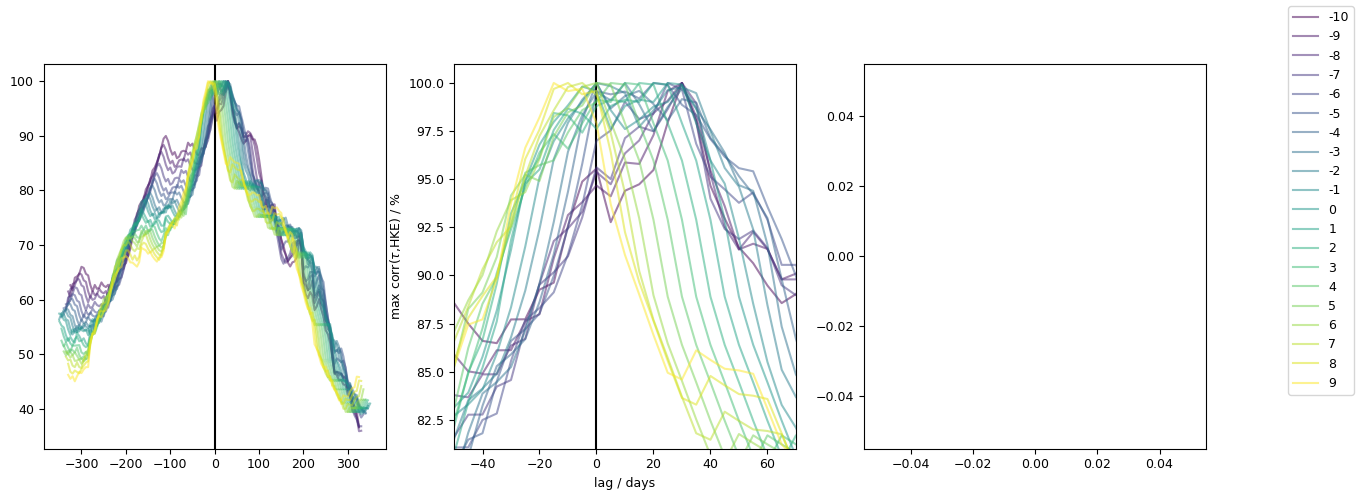

In [65]:
# Create 20 evenly spaced values in [0, 1]
n_colors = len(range(-10, 10))
gradient_values = np.linspace(0, 1, n_colors)

# Sample from a colormap (you can change 'viridis' to another)
cmap = matplotlib.colormaps.get_cmap("viridis")
colors = [np.array(cmap(val)) for val in gradient_values]

# Create a cycler with the colors
color_iter = itertools.cycle(cycler(color=colors))

# for _ in range(n_colors):
#     print(next(color_iter))

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))
ax[0].axvline(0, color="k")
ax[1].axvline(0, color="k")
ax[1].set_xlim(-50, 70)
ax[1].set_ylim(81, 101)
ax[1].set_xlabel("lag / days")
ax[1].set_ylabel("max corr($\\tau$,HKE) / %")

for x in range(-10, 10):
    if x > 0:
        corr2 = signal.correlate(
            momentum_transfer["C"].abs()[x:], hke["C", "2350"][:-x], mode="same"
        )
        corr2_in_percent = corr2 / np.nanmax(corr2) * 100
        lags2 = signal.correlation_lags(
            len(momentum_transfer["C"][x:]), len(hke["C", "2350"][:-x]), mode="same"
        )
    elif x == 0:
        corr2 = signal.correlate(momentum_transfer["C"].abs(), hke["C", "2350"], mode="same")
        corr2_in_percent = corr2 / np.nanmax(corr2) * 100
        lags2 = signal.correlation_lags(
            len(momentum_transfer["C"]), len(hke["C", "2350"]), mode="same"
        )
    else:
        corr2 = signal.correlate(
            momentum_transfer["C"].abs()[:x], hke["C", "2350"][-x:], mode="same"
        )
        corr2_in_percent = corr2 / np.nanmax(corr2) * 100
        lags2 = signal.correlation_lags(
            len(momentum_transfer["C"][:x]), len(hke["C", "2350"][-x:]), mode="same"
        )

    # there must be a simpler solution
    color = np.array(list(next(color_iter).values())).flatten()
    ax[0].plot(5 * lags2, corr2_in_percent, alpha=0.5, color=color, label=f"{x}")
    ax[1].plot(5 * lags2, corr2_in_percent, alpha=0.5, color=color)  # , label=f"{x}")

    if x % 3 == 0:
        ax[2].plot()
fig.legend()

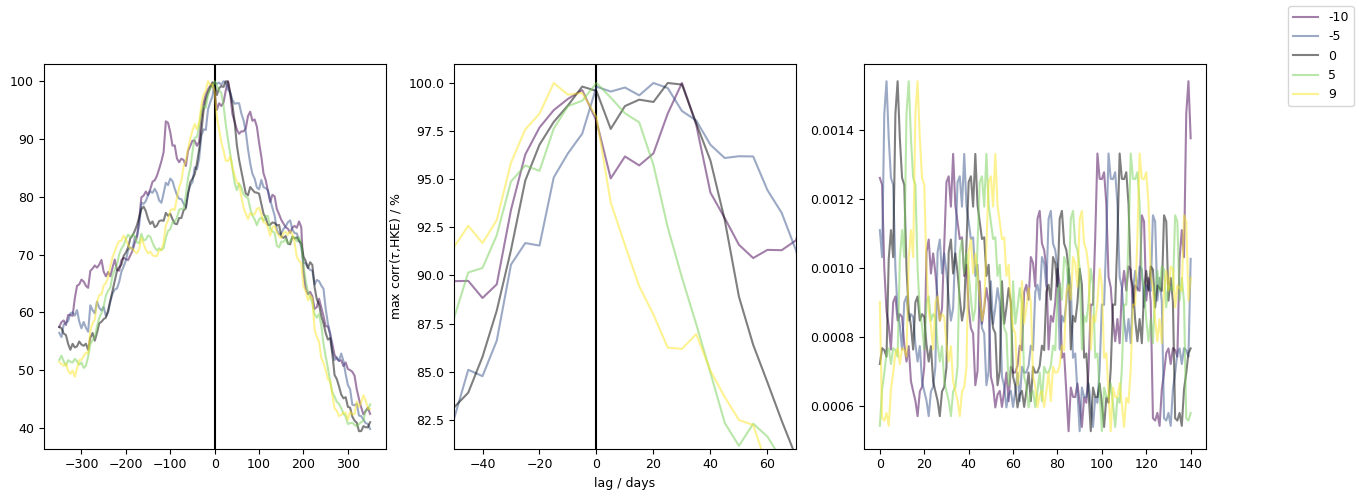

In [66]:
# Create 20 evenly spaced values in [0, 1]
n_colors = len(range(-10, 10))
gradient_values = np.linspace(0, 1, n_colors)

# Sample from a colormap (you can change 'viridis' to another)
cmap = matplotlib.colormaps.get_cmap("viridis")
colors = [np.array(cmap(val)) for val in gradient_values]

# Create a cycler with the colors
color_iter = itertools.cycle(cycler(color=colors))

# for _ in range(n_colors):
#     print(next(color_iter))

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))
ax[0].axvline(0, color="k")
ax[1].axvline(0, color="k")
ax[1].set_xlim(-50, 70)
ax[1].set_ylim(81, 101)
ax[1].set_xlabel("lag / days")
ax[1].set_ylabel("max corr($\\tau$,HKE) / %")

for x in range(-10, 10):
    # there must be a simpler solution
    color = np.array(list(next(color_iter).values())).flatten()

    if not (x % 5 == 0 or x == 9):
        continue

    corr2 = signal.correlate(
        momentum_transfer["C"].abs(), np.roll(hke["C", "2350"], x), mode="same"
    )
    corr2_in_percent = corr2 / np.nanmax(corr2) * 100
    lags2 = signal.correlation_lags(len(momentum_transfer["C"]), len(hke["C", "2350"]), mode="same")

    if x == 0:
        color = "k"
    ax[0].plot(5 * lags2, corr2_in_percent, alpha=0.5, color=color, label=f"{x}")
    ax[1].plot(5 * lags2, corr2_in_percent, alpha=0.5, color=color)  # , label=f"{x}")

    # if x%3==0:
    ax[2].plot(np.roll(hke["C", "2350"], x), color=color, alpha=0.5)
fig.legend()

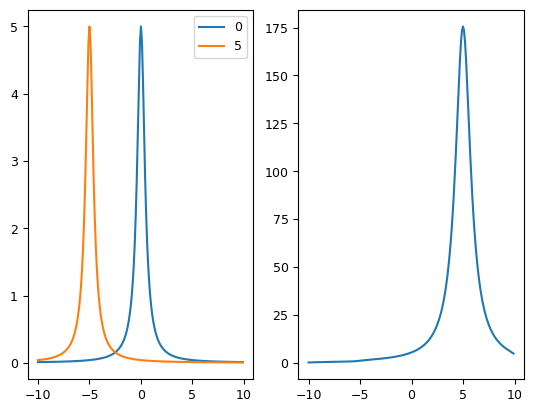

In [67]:
def f(x, k):
    return 1 / ((x + k) ** 2 + 0.2)


x = np.arange(-10, 10, 0.1)

shift = 5

cross = signal.correlate(f(x, 0), f(x, shift), mode="same")
lags = signal.correlation_lags(len(x), len(x), mode="same")
fig, ax = plt.subplots(ncols=2)

ax[0].plot(x, f(x, 0), label=f"{0}")
ax[0].plot(x, f(x, k=5), label=f"{shift}")
ax[0].legend()
ax[1].plot(lags * 0.1, cross)